# LabPics Chemistry Dataset Preview

This notebook explores `data/LabPics Chemistry`, visualizes the available ground-truth annotations, and lists candidate perception tasks for this dataset.

**Ground truth found in each sample folder:**
- `Image.jpg`: RGB laboratory image
- `Ignore.png`: regions excluded from evaluation/training
- `Data.json`: vessel, material, part, and relation metadata
- `SemanticMaps/FullImage/*.png`: class-level full-image semantic masks
- `Vessels/*.png`: vessel instance masks
- `MaterialsAndParts/*.png`: material and vessel-part instance masks

In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import json
import math
import random

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.patches import Patch

DATA_ROOT = Path('../data/LabPics Chemistry')
TRAIN_ROOT = DATA_ROOT / 'Train'
TEST_ROOT = DATA_ROOT / 'Test'
CATEGORIES_ROOT = DATA_ROOT / 'Categories'

assert DATA_ROOT.exists(), f'Dataset not found: {DATA_ROOT.resolve()}'
print(f'Dataset root: {DATA_ROOT.resolve()}')

Dataset root: /media/gregory/BigOne/vlm_datasets/LabPics Chemistry


## Helper Functions

In [2]:
def sample_dirs(split_root):
    return sorted([p for p in split_root.iterdir() if p.is_dir()])


def read_json(path):
    with open(path, 'r') as f:
        return json.load(f)


def load_image(sample_dir):
    return np.array(Image.open(sample_dir / 'Image.jpg').convert('RGB'))


def load_mask(path):
    if not path.exists():
        return None
    return np.array(Image.open(path).convert('L')) > 0


def mask_path(sample_dir, relative_mask_path):
    return sample_dir / relative_mask_path.lstrip('/')


def class_names_from_entry(entry):
    names = entry.get('All_ClassNames', [])
    return ', '.join(names) if names else '(no class names)'


def bbox_from_mask(mask):
    ys, xs = np.where(mask)
    if len(xs) == 0:
        return None
    return int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())


def overlay_mask(image, mask, color=(255, 60, 60), alpha=0.45):
    out = image.astype(np.float32).copy()
    color = np.array(color, dtype=np.float32)
    out[mask] = out[mask] * (1 - alpha) + color * alpha
    return np.clip(out, 0, 255).astype(np.uint8)


def overlay_many(image, masks, colors=None, alpha=0.45):
    if colors is None:
        cmap = plt.get_cmap('tab20')
        colors = [tuple(int(255 * x) for x in cmap(i % 20)[:3]) for i in range(len(masks))]
    out = image.astype(np.float32).copy()
    for mask, color in zip(masks, colors):
        if mask is None or not mask.any():
            continue
        c = np.array(color, dtype=np.float32)
        out[mask] = out[mask] * (1 - alpha) + c * alpha
    return np.clip(out, 0, 255).astype(np.uint8)


def add_mask_contours(ax, masks, colors=None, linewidth=1.6):
    if colors is None:
        cmap = plt.get_cmap('tab20')
        colors = [cmap(i % 20) for i in range(len(masks))]
    for mask, color in zip(masks, colors):
        if mask is not None and mask.any():
            ax.contour(mask.astype(float), levels=[0.5], colors=[color], linewidths=linewidth)


def get_semantic_masks(sample_dir):
    sem_dir = sample_dir / 'SemanticMaps' / 'FullImage'
    if not sem_dir.exists():
        return []
    return sorted(sem_dir.glob('*.png'))


def read_categories_txt():
    path = CATEGORIES_ROOT / 'CategoriesAndData.txt'
    if path.exists():
        return path.read_text().splitlines()
    return []


def plot_image_grid(sample_list, title, n_cols=5, max_items=25):
    samples = sample_list[:max_items]
    n = len(samples)
    n_cols = min(n_cols, max(1, n))
    n_rows = math.ceil(n / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.2 * n_cols, 2.6 * n_rows), squeeze=False)
    for ax, sample_dir in zip(axes.ravel(), samples):
        ax.imshow(load_image(sample_dir))
        ax.set_title(sample_dir.name, fontsize=9)
        ax.axis('off')
    for ax in axes.ravel()[n:]:
        ax.axis('off')
    fig.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    return fig


def plot_sample_overview(sample_dir, max_semantic=12):
    image = load_image(sample_dir)
    ignore = load_mask(sample_dir / 'Ignore.png')
    data = read_json(sample_dir / 'Data.json')
    vessel_masks = [load_mask(mask_path(sample_dir, v['MaskFilePath'])) for v in data.get('Vessels', {}).values()]
    part_masks = [load_mask(mask_path(sample_dir, m['MaskFilePath'])) for m in data.get('MaterialsAndParts', {}).values()]
    semantic_paths = get_semantic_masks(sample_dir)[:max_semantic]
    semantic_masks = [load_mask(p) for p in semantic_paths]
    semantic_labels = [p.stem for p in semantic_paths]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.ravel()
    axes[0].imshow(image)
    axes[0].set_title(f'{sample_dir.name}: image')

    axes[1].imshow(overlay_mask(image, ignore, color=(0, 0, 0), alpha=0.65) if ignore is not None else image)
    axes[1].set_title('Ignore mask overlay')

    axes[2].imshow(overlay_many(image, vessel_masks, alpha=0.45))
    add_mask_contours(axes[2], vessel_masks)
    axes[2].set_title(f'Vessel instances: {len(vessel_masks)}')

    axes[3].imshow(overlay_many(image, part_masks, alpha=0.45))
    add_mask_contours(axes[3], part_masks)
    axes[3].set_title(f'Materials and parts: {len(part_masks)}')

    axes[4].imshow(overlay_many(image, semantic_masks, alpha=0.40))
    axes[4].set_title(f'Full-image semantic masks: {len(get_semantic_masks(sample_dir))}')
    if semantic_labels:
        handles = [Patch(facecolor=plt.get_cmap('tab20')(i % 20), label=label) for i, label in enumerate(semantic_labels)]
        axes[4].legend(handles=handles, loc='upper left', bbox_to_anchor=(1.02, 1), fontsize=8)

    relation_canvas = image.copy()
    axes[5].imshow(relation_canvas)
    axes[5].set_title('Vessel/material bounding boxes and links')
    cmap = plt.get_cmap('tab20')
    for i, (vid, vessel) in enumerate(data.get('Vessels', {}).items()):
        mask = load_mask(mask_path(sample_dir, vessel['MaskFilePath']))
        bbox = bbox_from_mask(mask) if mask is not None else None
        color = cmap(i % 20)
        if bbox:
            x0, y0, x1, y1 = bbox
            axes[5].add_patch(plt.Rectangle((x0, y0), x1-x0, y1-y0, fill=False, color=color, linewidth=2))
            axes[5].text(x0, y0, f'V{vid}', color='white', fontsize=8, bbox=dict(facecolor=color, alpha=0.85, pad=1))
        for mid in vessel.get('VesselContentAll_Indx', []):
            material = data.get('MaterialsAndParts', {}).get(str(mid))
            if not material:
                continue
            mmask = load_mask(mask_path(sample_dir, material['MaskFilePath']))
            mbbox = bbox_from_mask(mmask) if mmask is not None else None
            if mbbox:
                mx0, my0, mx1, my1 = mbbox
                axes[5].add_patch(plt.Rectangle((mx0, my0), mx1-mx0, my1-my0, fill=False, color=color, linestyle='--', linewidth=1.5))
                axes[5].text(mx0, my1, f'M{mid}', color='white', fontsize=8, bbox=dict(facecolor=color, alpha=0.85, pad=1))

    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    return fig

## Dataset Overview

In [3]:
train_samples = sample_dirs(TRAIN_ROOT)
test_samples = sample_dirs(TEST_ROOT)
all_samples = train_samples + test_samples

print(f'Train samples: {len(train_samples)}')
print(f'Test samples:  {len(test_samples)}')
print(f'Total samples: {len(all_samples)}')

stats = []
semantic_counter = Counter()
vessel_class_counter = Counter()
material_class_counter = Counter()
part_class_counter = Counter()
relationship_counter = Counter()

for split_name, samples in [('Train', train_samples), ('Test', test_samples)]:
    for sample_dir in samples:
        data = read_json(sample_dir / 'Data.json')
        vessels = data.get('Vessels', {})
        materials = data.get('MaterialsAndParts', {})
        sem_paths = get_semantic_masks(sample_dir)
        stats.append({
            'split': split_name,
            'sample': sample_dir.name,
            'vessels': len(vessels),
            'materials_parts': len(materials),
            'semantic_masks': len(sem_paths),
        })
        semantic_counter.update([p.stem for p in sem_paths])
        for vessel in vessels.values():
            vessel_class_counter.update(vessel.get('VesselType_ClassNames', []))
            vessel_class_counter.update(vessel.get('Proprties_ClassNames', []))
            if vessel.get('ContainVessels_Indx'):
                relationship_counter['vessel contains vessel'] += len(vessel['ContainVessels_Indx'])
            if vessel.get('InsideOfVessels_Indx'):
                relationship_counter['vessel inside vessel'] += len(vessel['InsideOfVessels_Indx'])
            if vessel.get('LinkedToVessels_Indx'):
                relationship_counter['linked vessels'] += len(vessel['LinkedToVessels_Indx'])
            if vessel.get('VesselContentAll_Indx'):
                relationship_counter['vessel content links'] += len(vessel['VesselContentAll_Indx'])
        for item in materials.values():
            if item.get('IsPart'):
                part_class_counter.update(item.get('PartsType_ClassNames', []))
            else:
                material_class_counter.update(item.get('MaterialType_ClassNames', []))
                material_class_counter.update(item.get('Proprties_ClassNames', []))
            if item.get('InsideOfVessel_Indx'):
                relationship_counter['material/part inside vessel'] += len(item['InsideOfVessel_Indx'])
            if item.get('ContainMaterials_Indx'):
                relationship_counter['material contains material'] += len(item['ContainMaterials_Indx'])
            if item.get('InsideOfMaterials_Indx'):
                relationship_counter['material inside material'] += len(item['InsideOfMaterials_Indx'])

summary = {
    'avg_vessels_per_sample': np.mean([s['vessels'] for s in stats]),
    'avg_materials_parts_per_sample': np.mean([s['materials_parts'] for s in stats]),
    'avg_semantic_masks_per_sample': np.mean([s['semantic_masks'] for s in stats]),
    'max_vessels_in_sample': max(stats, key=lambda s: s['vessels']),
    'max_materials_parts_in_sample': max(stats, key=lambda s: s['materials_parts']),
    'max_semantic_masks_in_sample': max(stats, key=lambda s: s['semantic_masks']),
}
summary

Train samples: 3684
Test samples:  1374
Total samples: 5058


{'avg_vessels_per_sample': np.float64(2.0915381573744565),
 'avg_materials_parts_per_sample': np.float64(3.026097271648873),
 'avg_semantic_masks_per_sample': np.float64(9.491696322657177),
 'max_vessels_in_sample': {'split': 'Train',
  'sample': '3534Train',
  'vessels': 17,
  'materials_parts': 16,
  'semantic_masks': 18},
 'max_materials_parts_in_sample': {'split': 'Train',
  'sample': '328Train',
  'vessels': 5,
  'materials_parts': 41,
  'semantic_masks': 10},
 'max_semantic_masks_in_sample': {'split': 'Train',
  'sample': '2872Train',
  'vessels': 12,
  'materials_parts': 20,
  'semantic_masks': 26}}

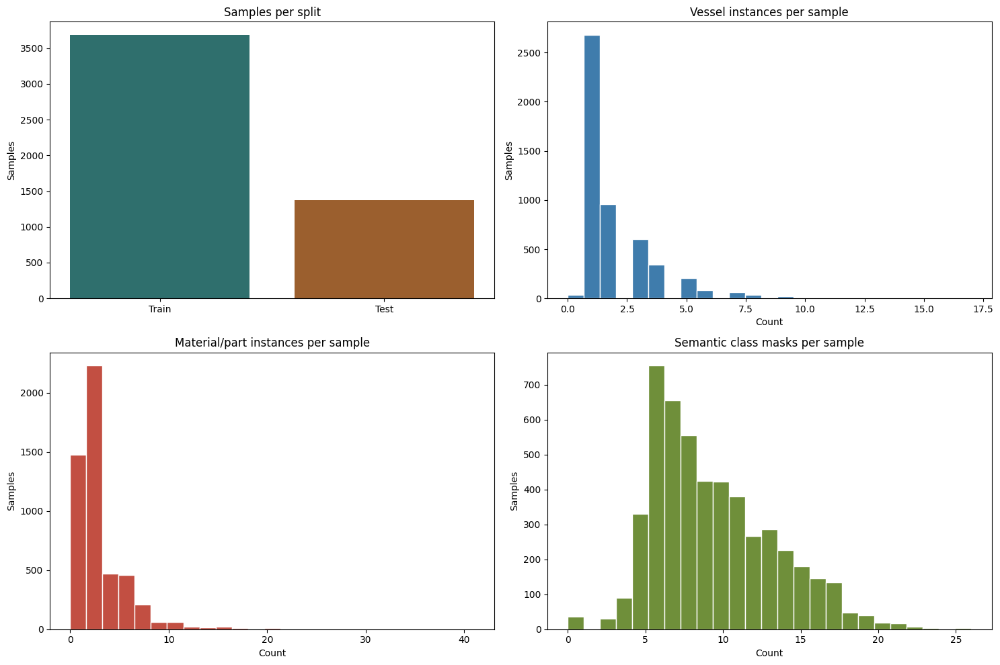

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

split_counts = Counter(s['split'] for s in stats)
axes[0].bar(split_counts.keys(), split_counts.values(), color=['#2f6f6d', '#9b5f2e'])
axes[0].set_title('Samples per split')
axes[0].set_ylabel('Samples')

for ax, key, title, color in [
    (axes[1], 'vessels', 'Vessel instances per sample', '#3f7cac'),
    (axes[2], 'materials_parts', 'Material/part instances per sample', '#c24f42'),
    (axes[3], 'semantic_masks', 'Semantic class masks per sample', '#6f8f3a'),
]:
    values = [s[key] for s in stats]
    ax.hist(values, bins=25, color=color, edgecolor='white')
    ax.set_title(title)
    ax.set_xlabel('Count')
    ax.set_ylabel('Samples')

plt.tight_layout()

## Category and Class Distributions

The dataset category files split labels into vessel type, vessel properties, vessel parts, material properties, and material type classes.

In [5]:
print('\n'.join(read_categories_txt()[:80]))

Vessel) CatID=1.   Notes: Vessel Type Class. 
Syringe) CatID=101.   Notes: Vessel Type Class. 
Pippete) CatID=102.   Notes: Vessel Type Class. 
Tube) CatID=103.   Notes: Vessel Type Class. 
IVBag) CatID=104.   Notes: Vessel Type Class. 
DripChamber) CatID=105.   Notes: Vessel Type Class. 
IVBottle) CatID=106.   Notes: Vessel Type Class. 
Beaker) CatID=107.   Notes: Vessel Type Class. 
RoundFlask) CatID=108.   Notes: Vessel Type Class. 
Cylinder) CatID=109.   Notes: Vessel Type Class. 
SeparatoryFunnel) CatID=110.   Notes: Vessel Type Class. 
Funnel) CatID=111.   Notes: Vessel Type Class. 
Burete) CatID=112.   Notes: Vessel Type Class. 
ChromatographyColumn) CatID=113.   Notes: Vessel Type Class. 
Condenser) CatID=114.   Notes: Vessel Type Class. 
Bottle) CatID=115.   Notes: Vessel Type Class. 
Jar) CatID=116.   Notes: Vessel Type Class. 
Connector) CatID=117	 Descrioption: Connetor use to connect two vessels..   Notes: Vessel Type Class. 
Flask) CatID=118.   Notes: Vessel Type Class. 


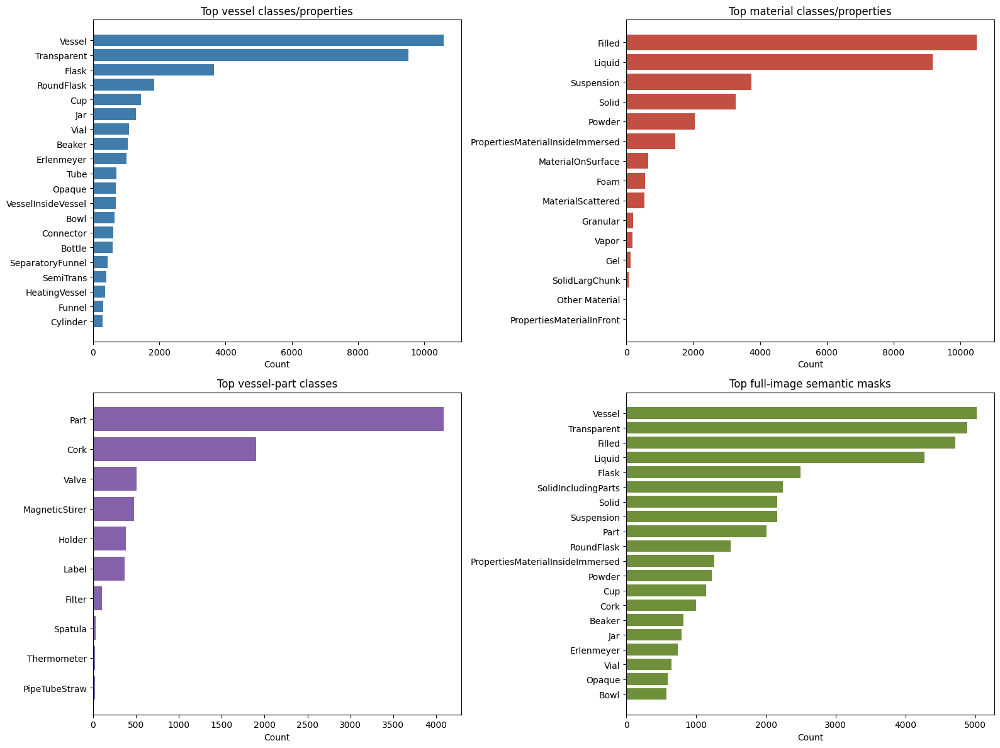

In [6]:
def plot_counter(counter, title, ax, top_n=20, color='#496a81'):
    items = counter.most_common(top_n)
    if not items:
        ax.axis('off')
        return
    labels, counts = zip(*items)
    y = np.arange(len(labels))
    ax.barh(y, counts, color=color)
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel('Count')

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plot_counter(vessel_class_counter, 'Top vessel classes/properties', axes[0, 0], color='#3f7cac')
plot_counter(material_class_counter, 'Top material classes/properties', axes[0, 1], color='#c24f42')
plot_counter(part_class_counter, 'Top vessel-part classes', axes[1, 0], color='#8561a9')
plot_counter(semantic_counter, 'Top full-image semantic masks', axes[1, 1], color='#6f8f3a')
plt.tight_layout()

## Many Image Examples

Change `MAX_EXAMPLES` if you want a denser or lighter grid. Large values can make notebook rendering slow.

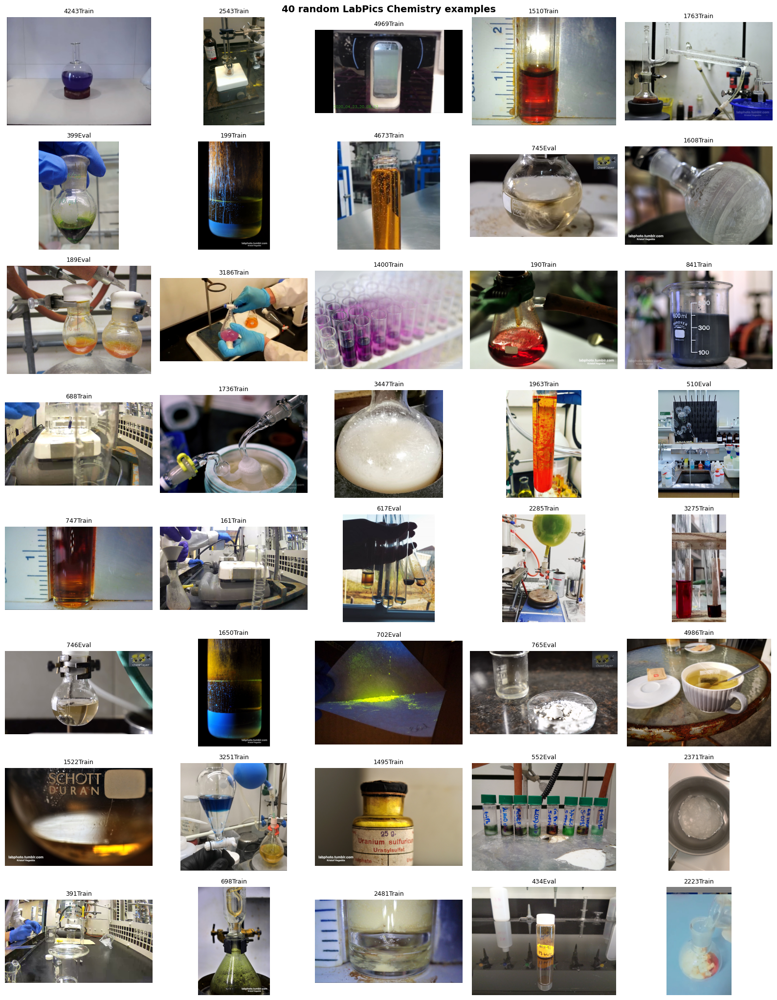

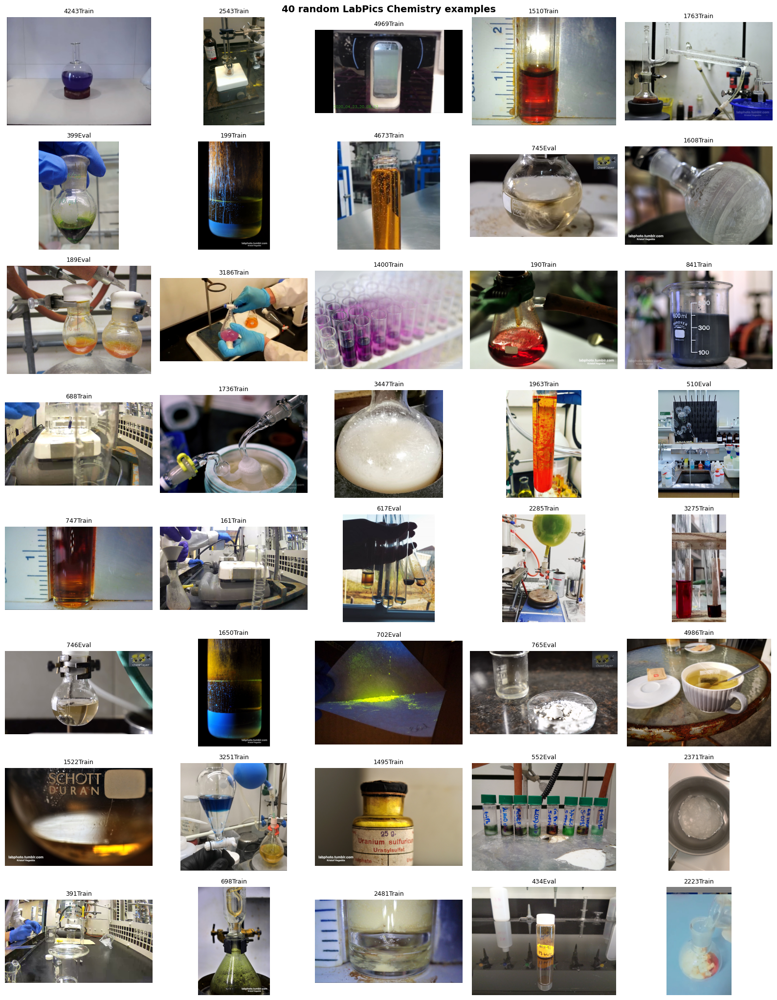

In [7]:
MAX_EXAMPLES = 40
random.seed(7)
example_samples = random.sample(all_samples, k=min(MAX_EXAMPLES, len(all_samples)))
plot_image_grid(example_samples, f'{len(example_samples)} random LabPics Chemistry examples', n_cols=5, max_items=MAX_EXAMPLES)

## Ground-Truth Visualization

Each row below shows the source image, ignored regions, vessel instances, material/part instances, full-image semantic masks, and simple bounding-box links from vessels to contained materials/parts.

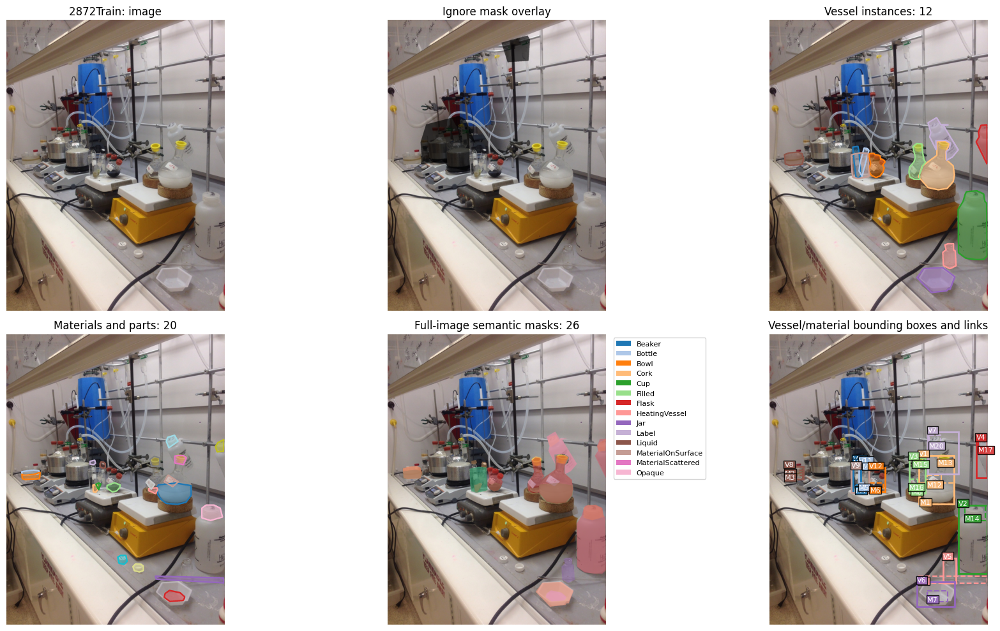

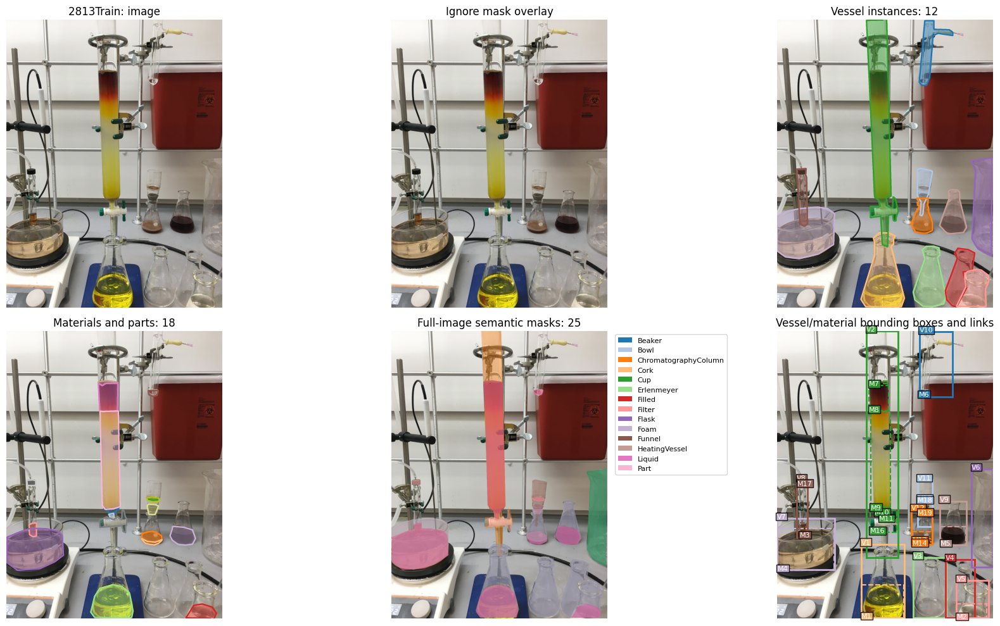

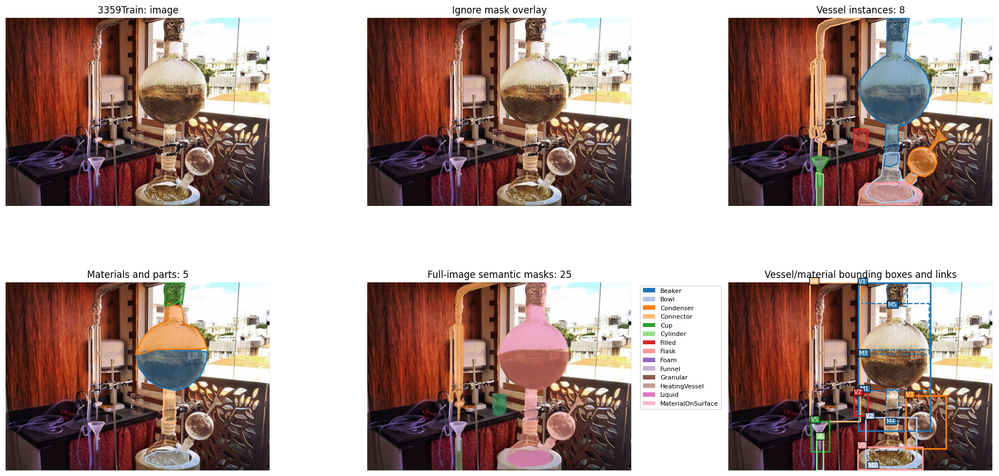

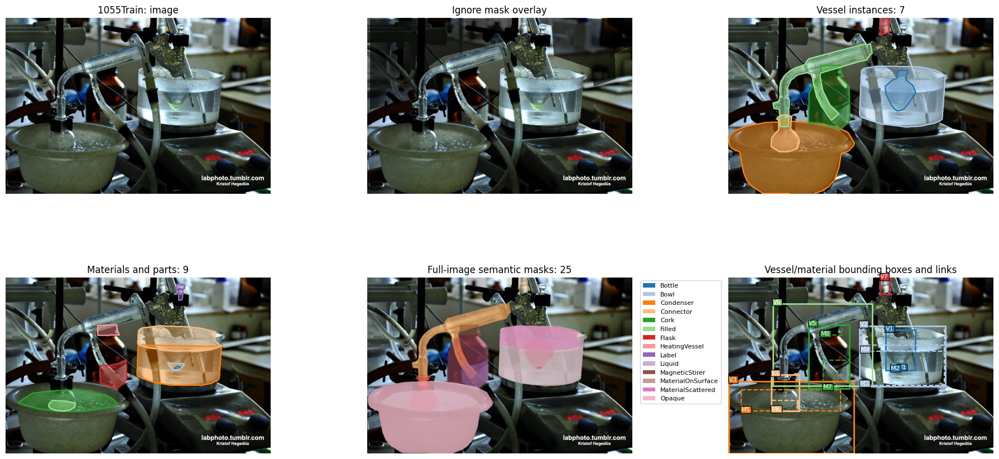

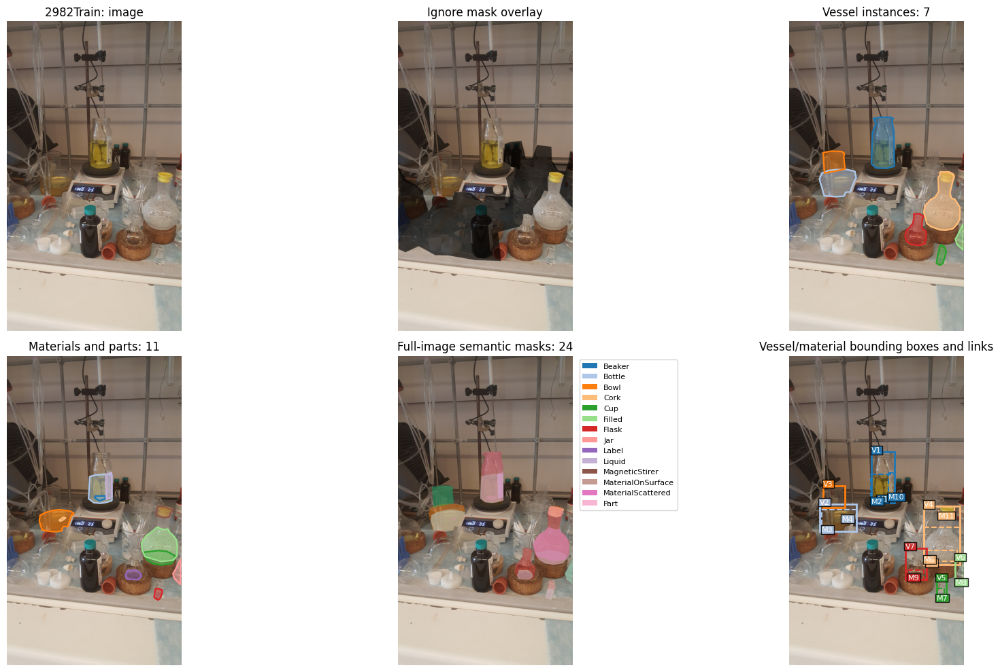

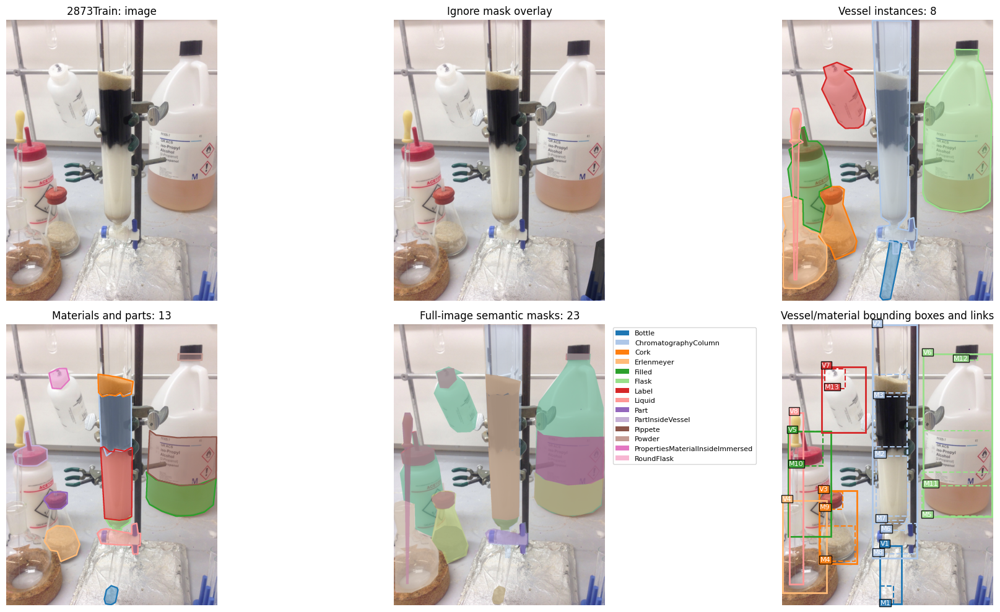

In [8]:
# Pick examples with richer annotation first.
rich_samples = sorted(
    all_samples,
    key=lambda p: (
        len(get_semantic_masks(p)),
        len(read_json(p / 'Data.json').get('Vessels', {})),
        len(read_json(p / 'Data.json').get('MaterialsAndParts', {})),
    ),
    reverse=True,
)

for sample_dir in rich_samples[:6]:
    plot_sample_overview(sample_dir, max_semantic=14)
    plt.show()

## Semantic Mask Gallery

This section overlays individual semantic masks. It is useful for inspecting exactly what each class covers.

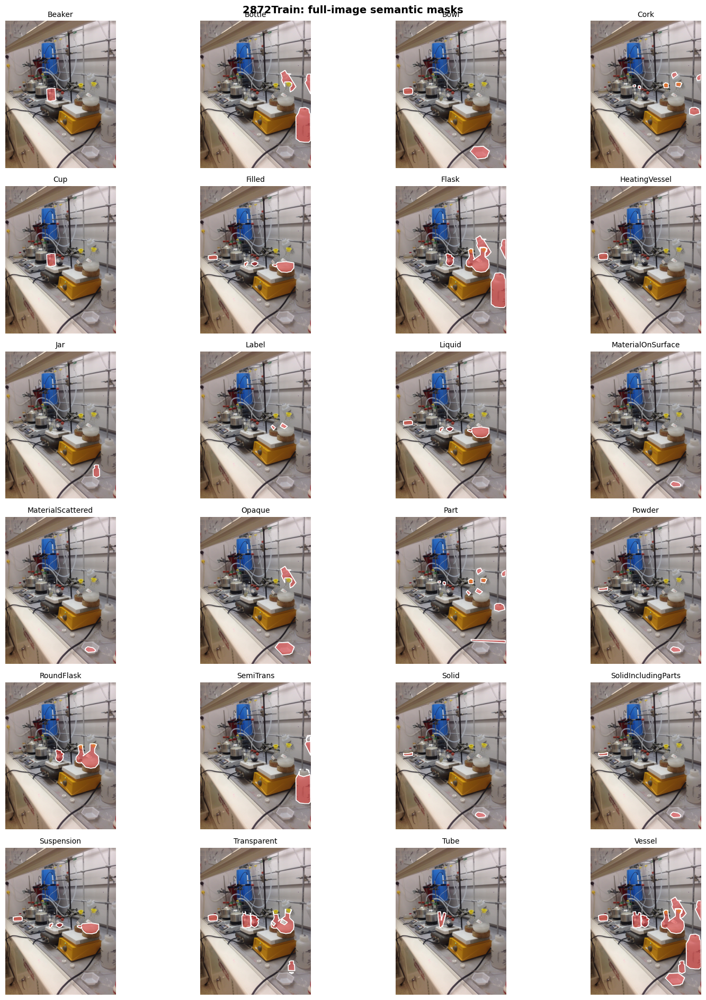

In [9]:
def plot_semantic_gallery(sample_dir, max_masks=24, n_cols=4):
    image = load_image(sample_dir)
    sem_paths = get_semantic_masks(sample_dir)[:max_masks]
    n = len(sem_paths)
    if n == 0:
        print(f'No semantic masks in {sample_dir.name}')
        return
    n_rows = math.ceil(n / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows), squeeze=False)
    for ax, sem_path in zip(axes.ravel(), sem_paths):
        mask = load_mask(sem_path)
        ax.imshow(overlay_mask(image, mask, color=(255, 70, 70), alpha=0.5))
        ax.contour(mask.astype(float), levels=[0.5], colors=['white'], linewidths=1.2)
        ax.set_title(sem_path.stem, fontsize=10)
        ax.axis('off')
    for ax in axes.ravel()[n:]:
        ax.axis('off')
    fig.suptitle(f'{sample_dir.name}: full-image semantic masks', fontsize=14, fontweight='bold')
    plt.tight_layout()

plot_semantic_gallery(rich_samples[0], max_masks=24, n_cols=4)

## Instance Metadata Inspection

Use this to inspect the exact `Data.json` records for a sample, including class names, transparency, vessel-content links, and material/part relation fields.

In [10]:
def print_sample_metadata(sample_dir, max_vessels=12, max_materials=20):
    data = read_json(sample_dir / 'Data.json')
    print(f'Sample: {sample_dir.name}')
    print(f'Vessels: {len(data.get("Vessels", {}))}')
    for vid, vessel in list(data.get('Vessels', {}).items())[:max_vessels]:
        print(f'  V{vid}: {class_names_from_entry(vessel)} | contents={vessel.get("VesselContentAll_Indx", [])} | linked={vessel.get("LinkedToVessels_Indx", [])}')
    print(f'\nMaterials/parts: {len(data.get("MaterialsAndParts", {}))}')
    for mid, item in list(data.get('MaterialsAndParts', {}).items())[:max_materials]:
        kind = 'part' if item.get('IsPart') else 'material'
        print(f'  M{mid} ({kind}): {class_names_from_entry(item)} | inside_vessels={item.get("InsideOfVessel_Indx", [])}')

print_sample_metadata(rich_samples[0])

Sample: 2872Train
Vessels: 12
  V10: Vessel, Tube, VesselInsideVessel, Transparent | contents=[4, 10] | linked=[]
  V11: Vessel, Tube, VesselInsideVessel, Transparent | contents=[5, 11] | linked=[]
  V12: Vessel, RoundFlask, Flask, Transparent | contents=[6] | linked=[]
  V1: Vessel, RoundFlask, Flask, Transparent | contents=[1, 12, 13] | linked=[]
  V2: Vessel, Bottle, Flask, SemiTrans | contents=[14] | linked=[]
  V3: Vessel, RoundFlask, Flask, Transparent | contents=[8, 15, 16] | linked=[]
  V4: Vessel, Bottle, Flask, SemiTrans | contents=[17] | linked=[]
  V5: Vessel, Jar, Vial, Transparent | contents=[9] | linked=[]
  V6: Vessel, Bowl, Opaque | contents=[7] | linked=[]
  V7: Vessel, Bottle, Flask, Opaque | contents=[20] | linked=[]
  V8: Vessel, Bowl, HeatingVessel, Transparent | contents=[2, 3] | linked=[]
  V9: Vessel, Beaker, Cup, Transparent | contents=[] | linked=[]

Materials/parts: 20
  M1 (material): Liquid, Suspension, Filled | inside_vessels=[1]
  M2 (material): Liquid, 

## Relationship and Task Signals

In [11]:
print('Relationship counts:')
for name, count in relationship_counter.most_common():
    print(f'  {name}: {count}')

print('\nSamples with most vessels:')
for row in sorted(stats, key=lambda s: s['vessels'], reverse=True)[:10]:
    print(f"  {row['sample']} ({row['split']}): vessels={row['vessels']}, materials/parts={row['materials_parts']}, semantic={row['semantic_masks']}")

print('\nSamples with most materials/parts:')
for row in sorted(stats, key=lambda s: s['materials_parts'], reverse=True)[:10]:
    print(f"  {row['sample']} ({row['split']}): vessels={row['vessels']}, materials/parts={row['materials_parts']}, semantic={row['semantic_masks']}")

Relationship counts:
  vessel content links: 15350
  material/part inside vessel: 15350
  linked vessels: 2132
  material contains material: 1358
  material inside material: 1351
  vessel inside vessel: 609
  vessel contains vessel: 609

Samples with most vessels:
  3534Train (Train): vessels=17, materials/parts=16, semantic=18
  395Train (Train): vessels=17, materials/parts=17, semantic=10
  3528Train (Train): vessels=15, materials/parts=7, semantic=14
  212Eval (Test): vessels=15, materials/parts=16, semantic=11
  2962Train (Train): vessels=14, materials/parts=14, semantic=17
  2025Train (Train): vessels=13, materials/parts=9, semantic=20
  2578Train (Train): vessels=13, materials/parts=7, semantic=19
  214Eval (Test): vessels=13, materials/parts=21, semantic=17
  456Eval (Test): vessels=13, materials/parts=6, semantic=7
  151Train (Train): vessels=12, materials/parts=20, semantic=9

Samples with most materials/parts:
  328Train (Train): vessels=5, materials/parts=41, semantic=10
  3

## Potential Tasks for LabPics Chemistry

Grounded in the annotations present here, this dataset can support:

1. **Full-image semantic segmentation**: predict class masks such as `Vessel`, `Liquid`, `Powder`, `Transparent`, `Beaker`, `Funnel`, `SolidIncludingParts`, and other classes in `SemanticMaps/FullImage`.
2. **Vessel instance segmentation**: segment individual vessels from `Vessels/*.png`, including overlapping/linked laboratory glassware.
3. **Material and vessel-part instance segmentation**: segment liquids, powders, solids, labels, holders, stirrers, filters, and other contents from `MaterialsAndParts/*.png`.
4. **Vessel type classification**: classify instance masks into beaker, flask, round flask, cylinder, separatory funnel, vial, dish, tube, connector, condenser, etc.
5. **Transparency/property classification**: classify vessels as transparent, semi-transparent, opaque, disturbed view, or vessel-inside-vessel using `Proprties_ClassNames`.
6. **Material phase/type classification**: classify contained material as liquid, suspension, foam, solid, powder, gel, granular, vapor, blood, urine, and filled regions.
7. **Vessel-content relationship prediction**: infer which materials/parts are inside each vessel using `VesselContentAll_Indx`, `VesselContentMaterial_Indx`, `VesselContentParts_Indx`, and `InsideOfVessel_Indx`.
8. **Linked/connected vessel reasoning**: detect vessel pairs connected by funnels, tubing, condensers, or apparatus links using `LinkedToVessels_Indx` and related vessel fields.
9. **Nested-object reasoning**: predict vessel-inside-vessel and material-inside-material relations where annotated.
10. **Ignore-region aware evaluation/training**: train or evaluate models while masking `Ignore.png` regions.
11. **Prompted VLM evaluation**: ask models to localize vessels/materials, name apparatus, identify contents, count instances, or answer relation questions from the image.
12. **SAM/SAM2 prompt quality tests**: use boxes/points from these masks to evaluate how well foundation segmentation models recover transparent vessels and fluid boundaries.
13. **Open-vocabulary segmentation/classification**: compare class-name prompts against ground-truth masks and metadata.
14. **Lab safety/automation perception pretraining**: use vessel/material/part segmentation as a proxy task before downstream robotic lab manipulation, liquid-level, or apparatus-state tasks.